# Experiment 5: Mean, Median, Standard Deviation and Skewness of All Attributes

**Roll no.:** 16014324022  
**Dataset:** `irrigation_prediction.csv`  
**Reference:** `DS_EXP5.ipynb`

**Aim:** Calculate mean, median, sample standard deviation and skewness for every numeric irrigation attribute, visualize each distribution with a histogram and KDE, and summarize every categorical attribute using frequencies.

This notebook follows the reference's load, inspect, descriptive statistics, skewness, visualization and inference sequence using the supplied irrigation data. Statistics describe this CSV; the reference weather workbook is not required.


## 1. Load the Dataset

Keep `irrigation_prediction.csv` in the notebook's working directory. The source file is read without modification.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = Path('irrigation_prediction.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Run the notebook from the folder containing irrigation_prediction.csv.')
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()


Shape: (10000, 20)


,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


In [2]:
print('Data types:')
print(df.dtypes)
print('\nMissing values by attribute:')
print(df.isna().sum())
print('\nTotal missing values:', int(df.isna().sum().sum()))


Data types:
Soil_Type                   object
Soil_pH                    float64
Soil_Moisture              float64
Organic_Carbon             float64
Electrical_Conductivity    float64
Temperature_C              float64
Humidity                   float64
Rainfall_mm                float64
Sunlight_Hours             float64
Wind_Speed_kmh             float64
Crop_Type                   object
Crop_Growth_Stage           object
Season                      object
Irrigation_Type             object
Water_Source                object
Field_Area_hectare         float64
Mulching_Used               object
Previous_Irrigation_mm     float64
Region                      object
Irrigation_Need             object
dtype: object

Missing values by attribute:
Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hou

In [3]:
# Inspect missingness instead of applying weather-specific imputation.
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
assert np.isfinite(df[num_cols].to_numpy()).all(), 'Review missing or infinite numeric values.'
assert not df.isna().any().any(), 'Review missing values before continuing.'
print('All records are complete; no imputation is needed.')
print(f'Numeric attributes ({len(num_cols)}):', num_cols)
print(f'Categorical attributes ({len(cat_cols)}):', cat_cols)


All records are complete; no imputation is needed.
Numeric attributes (11): ['Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm']
Categorical attributes (9): ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region', 'Irrigation_Need']


**Inference:** There are **10,000 records and 20 attributes**: **11 numeric** and **9 categorical**, with no missing values. All numeric fields vary and contain measurements rather than identifiers. `Irrigation_Need` has ordered labels Low, Medium and High, but their numerical spacing is undefined, so these labels are summarized using counts and percentages.


## 2. Mean, Median and Standard Deviation of Each Numeric Attribute

- **Mean:** arithmetic average, $\bar{x}=\sum x_i/n$.
- **Median:** middle sorted value, or the average of the two middle values for even $n$.
- **Sample standard deviation:** $s=\sqrt{\sum(x_i-\bar{x})^2/(n-1)}$, using `ddof=1`.

Minimum and maximum provide context. Standard deviations retain the original units and should not be compared directly across different units.


In [4]:
stats_table = pd.DataFrame({
    'Count': df[num_cols].count(),
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Std_Dev': df[num_cols].std(ddof=1),
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max()
})
stats_table.round(3)


,Count,Mean,Median,Std_Dev,Min,Max
Soil_pH,10000,6.488,6.470,0.980,4.80,8.20
Soil_Moisture,10000,36.969,37.240,16.431,8.00,65.00
Organic_Carbon,10000,0.945,0.950,0.372,0.30,1.60
Electrical_Conductivity,10000,1.792,1.780,0.984,0.10,3.50
Temperature_C,10000,26.991,27.090,8.664,12.00,42.00
Humidity,10000,60.080,60.040,20.188,25.00,95.00
Rainfall_mm,10000,1252.499,1250.335,715.582,0.38,2499.69
Sunlight_Hours,10000,7.519,7.560,2.016,4.00,11.00
Wind_Speed_kmh,10000,10.164,10.190,5.671,0.50,20.00
Field_Area_hectare,10000,7.598,7.540,4.234,0.30,15.00


**Inference:** Mean and median are close for every numeric attribute. `Soil_Moisture` has mean **36.969** and median **37.240**; `Temperature_C` has mean **26.991** and median **27.090**. `Rainfall_mm` has mean **1252.499**, median **1250.335**, and sample standard deviation **715.582 mm**. Its large numerical spread reflects its broad range and unit, and does not by itself imply high skewness. The CSV does not specify the rainfall recording period, so these values are not interpreted as daily rainfall.


## 3. Skewness of Each Numeric Attribute

Skewness measures distribution asymmetry. SciPy's **bias-corrected Fisher-Pearson sample skewness** (`bias=False`) is used, consistent with `pandas.Series.skew()` for these complete numeric columns.

Descriptive heuristic bands: $|\mathrm{skew}|<0.5$ is approximately symmetric, $0.5\leq|\mathrm{skew}|<1$ is moderately skewed, and $|\mathrm{skew}|\geq1$ is strongly skewed. Positive values indicate a longer right tail; negative values indicate a longer left tail. These bands are not a normality test.


In [5]:
def describe_skewness(value):
    if abs(value) < 0.5:
        return 'Approximately symmetric'
    direction = 'right' if value > 0 else 'left'
    degree = 'Moderately' if abs(value) < 1 else 'Strongly'
    return f'{degree} {direction}-skewed'

skew_table = pd.DataFrame({
    'Skewness': [skew(df[col].to_numpy(), bias=False) for col in num_cols]
}, index=num_cols)
skew_table.index.name = 'Attribute'
skew_table['Interpretation'] = skew_table['Skewness'].map(describe_skewness)
skew_table = skew_table.sort_values('Skewness', ascending=False)
skew_table.round(4)


,Skewness,Interpretation
Attribute,,
Soil_pH,0.0274,Approximately symmetric
Electrical_Conductivity,0.0195,Approximately symmetric
Organic_Carbon,0.0156,Approximately symmetric
Field_Area_hectare,0.0122,Approximately symmetric
Wind_Speed_kmh,0.0120,Approximately symmetric
Previous_Irrigation_mm,0.0068,Approximately symmetric
Humidity,-0.0067,Approximately symmetric
Temperature_C,-0.0114,Approximately symmetric
Rainfall_mm,-0.0127,Approximately symmetric


**Inference:** All 11 numeric attributes are approximately symmetric under this rule. Skewness ranges from **-0.0398** for `Soil_Moisture` to **+0.0274** for `Soil_pH`; these small signs describe only slight sample asymmetry. `Rainfall_mm` has skewness **-0.0127**, unlike the highly right-skewed rainfall in the reference weather dataset. Near-zero skewness does not prove a normal distribution or the absence of outliers.


## 4. Visualizing Skewness: Histogram and KDE for Every Numeric Attribute

Each panel shows a histogram, a kernel density estimate (KDE), the mean (red dashed line) and the median (green dotted line). KDE is a smoothed estimate and may extend slightly beyond observed bounds.


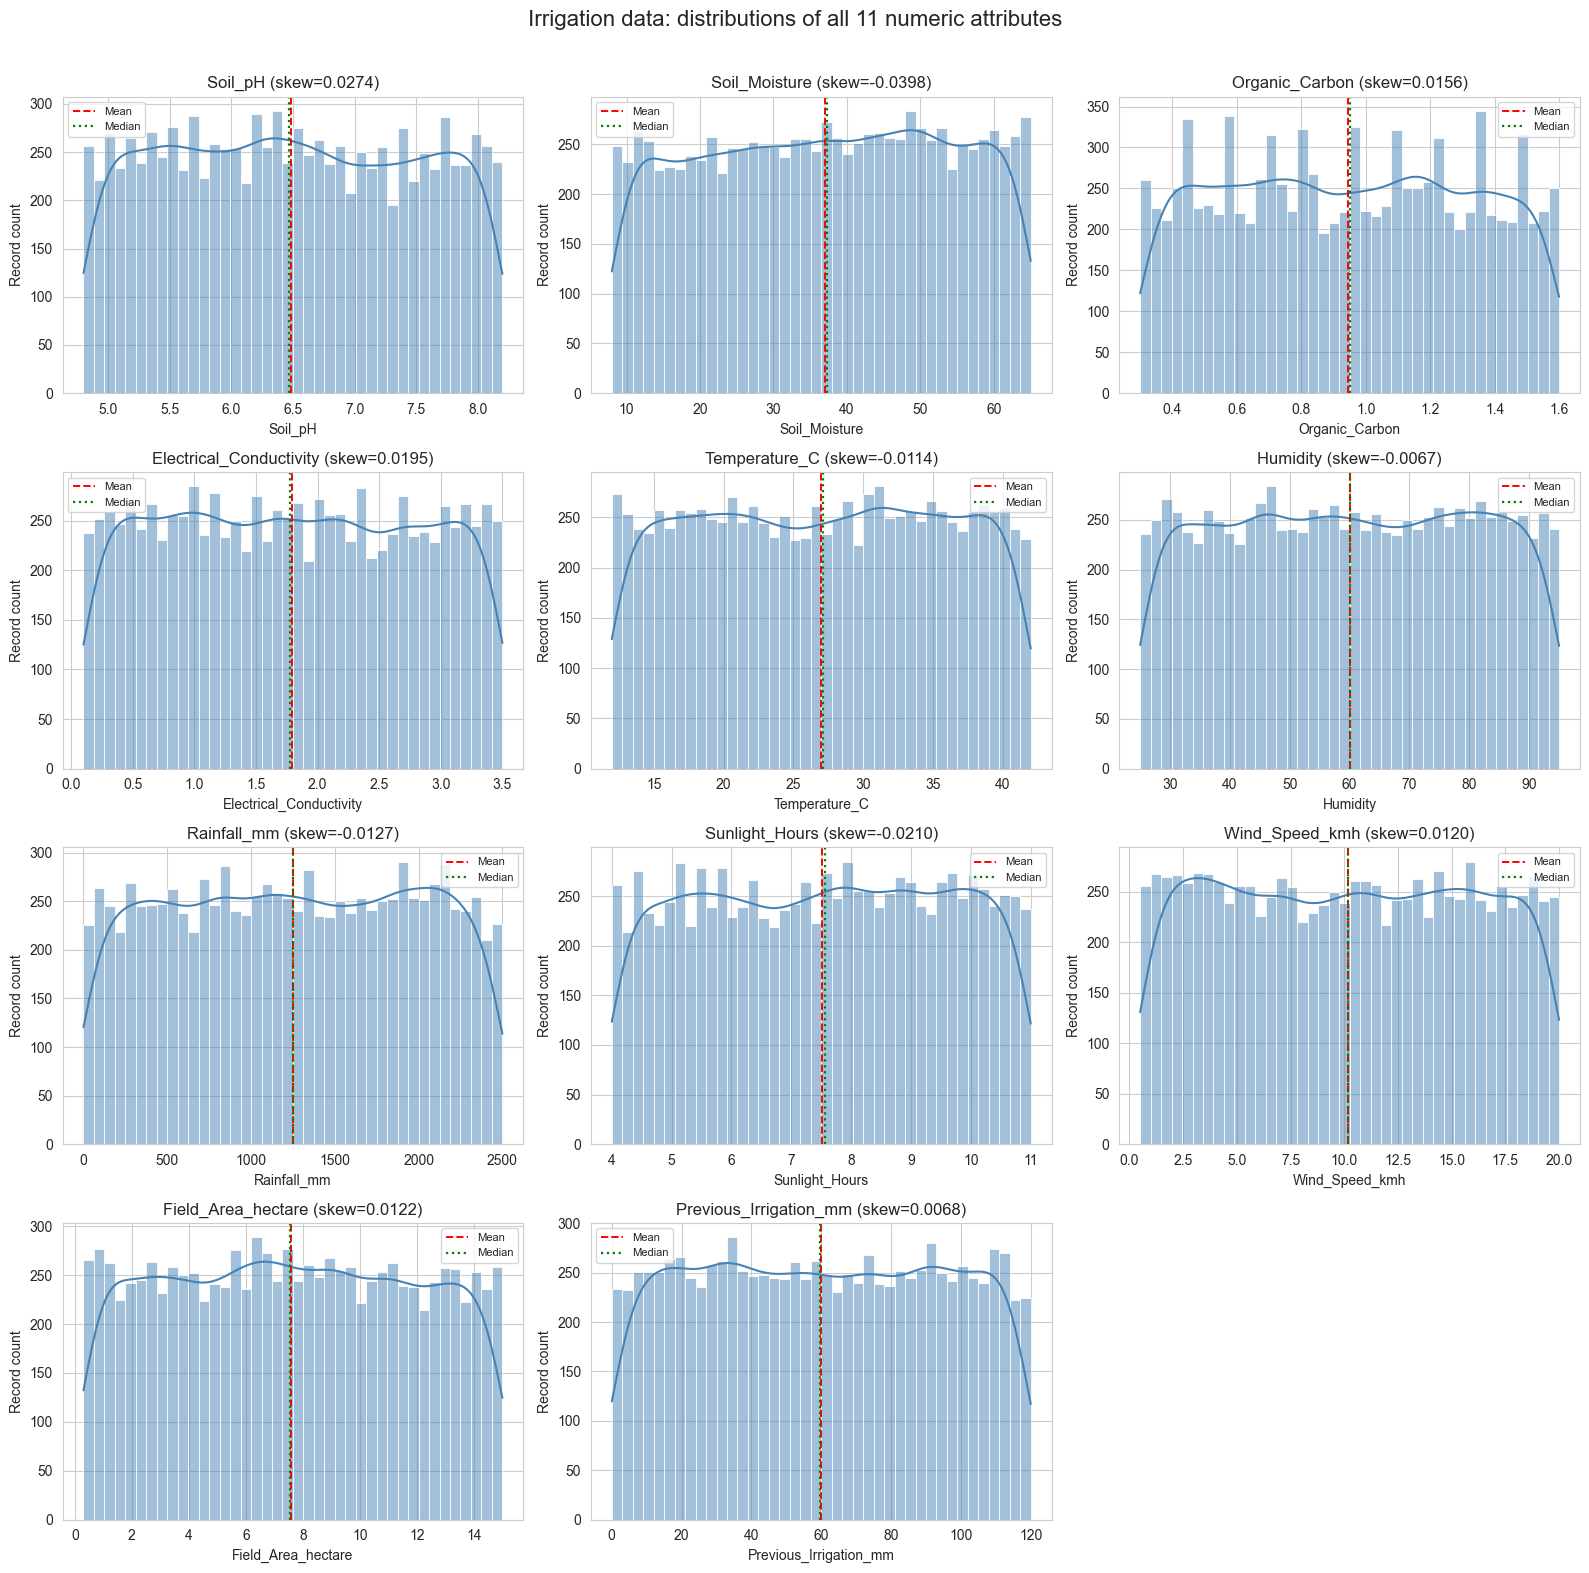

In [6]:
ncols = 3
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='steelblue', bins=40)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.4, label='Mean')
    ax.axvline(df[col].median(), color='green', linestyle=':', linewidth=1.6, label='Median')
    ax.set_title(f'{col} (skew={skew_table.loc[col, "Skewness"]:.4f})')
    ax.set_xlabel(col)
    ax.set_ylabel('Record count')
    ax.legend(fontsize=8)
for ax in axes[len(num_cols):]:
    fig.delaxes(ax)
fig.suptitle('Irrigation data: distributions of all 11 numeric attributes', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


**Inference:** Mean and median lines nearly overlap, consistent with the small skewness values. Histograms are broadly flat across the observed ranges rather than distinctly bell-shaped. Symmetry therefore should not be interpreted as evidence of normality. These plots describe the supplied data; they do not establish a probability model for real field measurements.


## 5. Frequency Summary of Every Categorical Attribute

Arithmetic mean, standard deviation and moment skewness are not meaningful for category names. Use modes, counts and percentages instead. Low, Medium and High are displayed in their natural order without assigning artificial numeric distances.


In [7]:
frequency_parts = []
for col in cat_cols:
    counts = df[col].value_counts(dropna=False)
    if col == 'Irrigation_Need':
        counts = counts.reindex(['Low', 'Medium', 'High'], fill_value=0)
    frequency_parts.append(pd.DataFrame({
        'Attribute': col,
        'Category': counts.index,
        'Count': counts.to_numpy(),
        'Percentage': counts.to_numpy() / len(df) * 100
    }))
frequency_table = pd.concat(frequency_parts, ignore_index=True)
frequency_table.style.format({'Percentage': '{:.2f}%'})


,Attribute,Category,Count,Percentage
0,Soil_Type,Sandy,2536,25.36%
1,Soil_Type,Silt,2501,25.01%
2,Soil_Type,Loamy,2486,24.86%
3,Soil_Type,Clay,2477,24.77%
4,Crop_Type,Rice,1711,17.11%
5,Crop_Type,Maize,1694,16.94%
6,Crop_Type,Sugarcane,1678,16.78%
7,Crop_Type,Potato,1663,16.63%
8,Crop_Type,Wheat,1659,16.59%
9,Crop_Type,Cotton,1595,15.95%


In [8]:
categorical_summary = pd.DataFrame({
    'Distinct_categories': df[cat_cols].nunique(),
    'Mode': [df[col].mode().iloc[0] for col in cat_cols],
    'Mode_count': [df[col].value_counts().iloc[0] for col in cat_cols]
})
categorical_summary['Mode_percentage'] = categorical_summary['Mode_count'] / len(df) * 100
categorical_summary.round(2)


,Distinct_categories,Mode,Mode_count,Mode_percentage
Soil_Type,4,Sandy,2536,25.36
Crop_Type,6,Rice,1711,17.11
Crop_Growth_Stage,4,Harvest,2581,25.81
Season,3,Rabi,3383,33.83
Irrigation_Type,4,Sprinkler,2527,25.27
Water_Source,4,River,2528,25.28
Mulching_Used,2,No,5013,50.13
Region,5,South,2102,21.02
Irrigation_Need,3,Low,5864,58.64


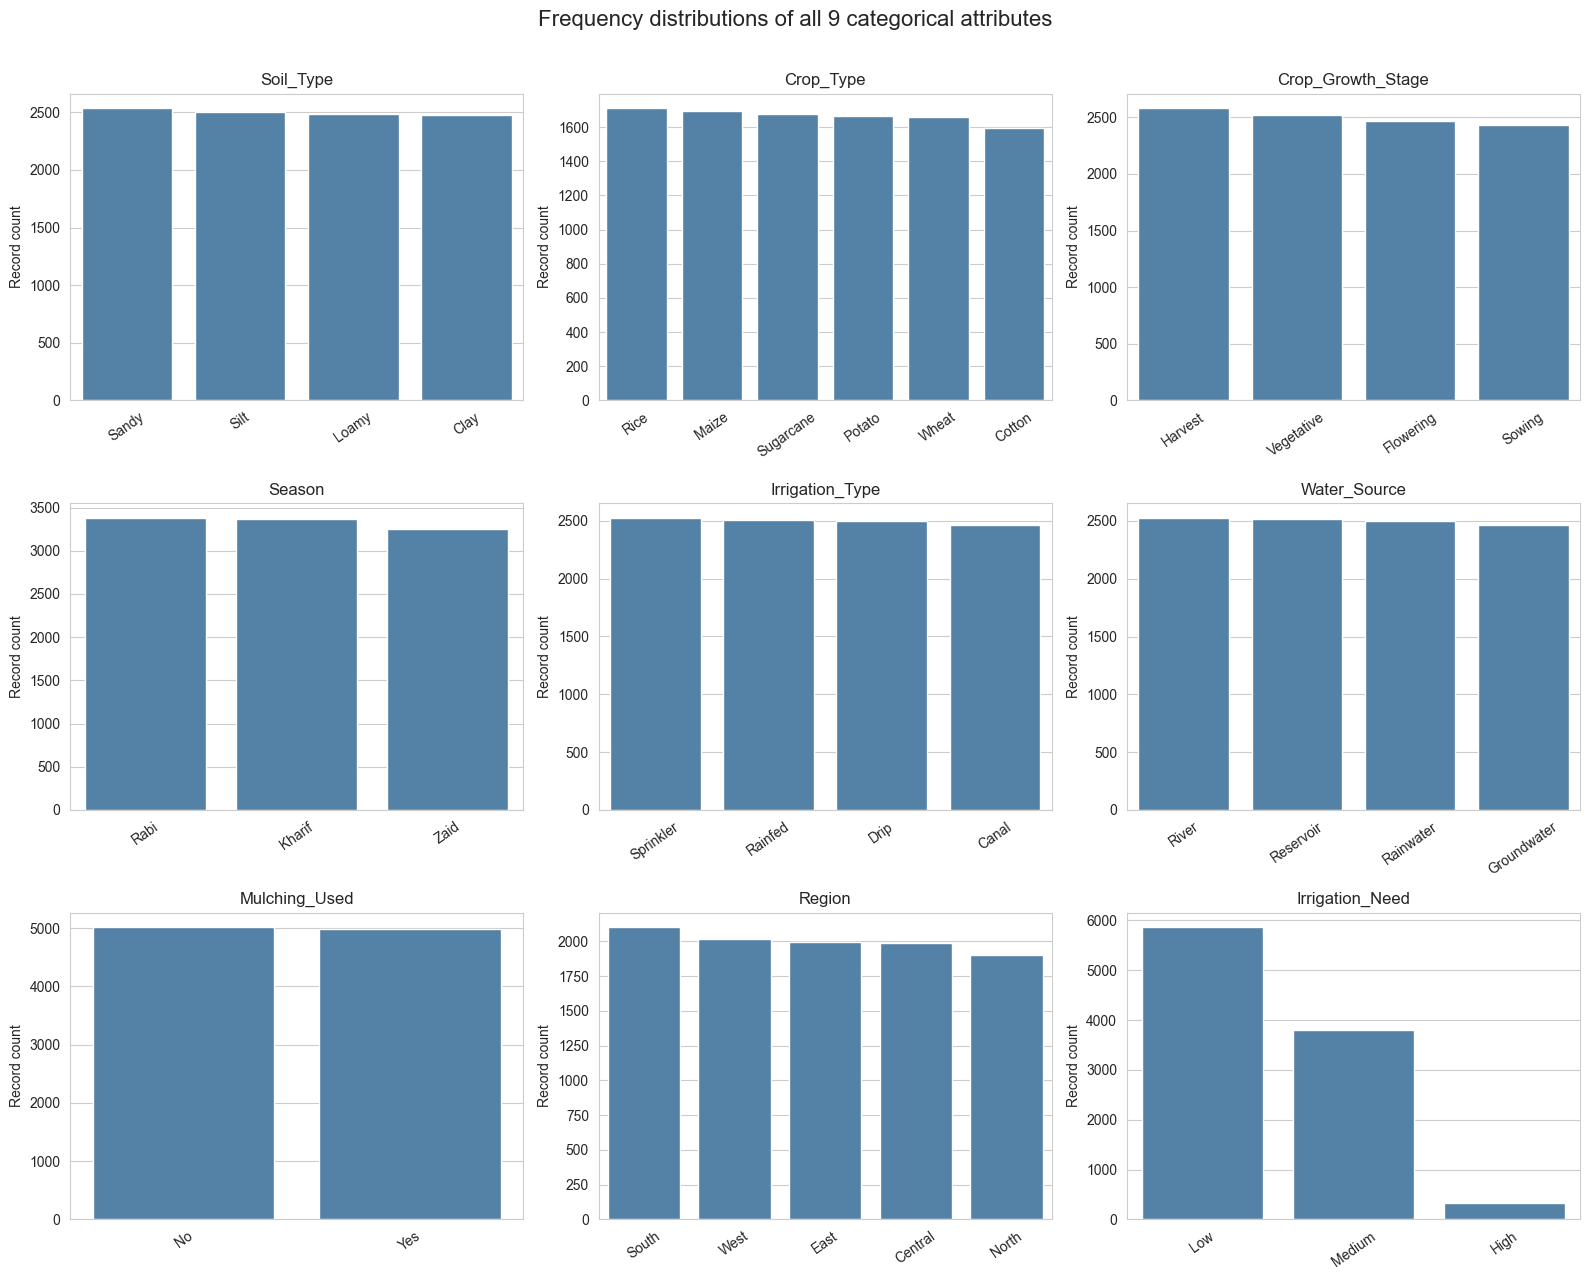

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.ravel(), cat_cols):
    counts = frequency_table.loc[frequency_table['Attribute'].eq(col)]
    sns.barplot(data=counts, x='Category', y='Count', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Record count')
    ax.tick_params(axis='x', labelrotation=35)
fig.suptitle('Frequency distributions of all 9 categorical attributes', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


**Inference:** Input categories have broadly similar frequencies within each attribute, but `Irrigation_Need` is imbalanced: **Low = 5,864 (58.64%)**, **Medium = 3,800 (38.00%)**, and **High = 336 (3.36%)**. A later classification task should account for the small High class and report class-wise performance. This experiment is descriptive; no prediction model is trained or evaluated.


## 6. Validate the Analysis

Check that every attribute is covered, all category totals equal the dataset size, and independently computed skewness agrees with the reported table.


In [10]:
assert df.shape == (10000, 20)
assert len(num_cols) == 11 and len(cat_cols) == 9
assert set(num_cols).isdisjoint(cat_cols)
assert set(num_cols + cat_cols) == set(df.columns)
assert stats_table['Count'].eq(len(df)).all()
assert set(skew_table.index) == set(num_cols)
assert frequency_table.groupby('Attribute')['Count'].sum().eq(len(df)).all()
assert np.allclose(frequency_table.groupby('Attribute')['Percentage'].sum(), 100)
assert np.allclose(skew_table.loc[num_cols, 'Skewness'], df[num_cols].skew())
assert np.isfinite(stats_table.to_numpy()).all()
print('Validation passed: all 20 attributes covered; counts and skewness verified.')


Validation passed: all 20 attributes covered; counts and skewness verified.


## Overall Inference

- All **11 numeric attributes** were analyzed for mean, median, sample standard deviation and skewness, with a histogram and KDE for each. All **9 categorical attributes** were summarized using frequencies, percentages and modes.
- Every numeric attribute has small absolute skewness (**less than 0.04**) and close mean and median values. Observed shapes are broadly flat; skewness alone does not establish normality.
- `Rainfall_mm` is approximately symmetric in this CSV. The reference weather dataset's highly right-skewed rainfall conclusion does not apply here.
- Standard deviation describes spread in the original units. Scaling may be relevant for future scale-sensitive models; a log transform is not justified by skewness alone for these columns.
- The target `Irrigation_Need` is imbalanced, especially the High class (3.36%). These descriptive results guide later analysis without claiming predictive accuracy or field validation.
